# 01 · Exploratory Data Analysis (EDA) & Pembersihan Data
**Kasus 01:** Pengendalian Mutu *Injection Molding* (MKB UPI)

Notebook ini mengaudit `data/raw.csv` (25.350 baris), memperbaiki anomali pencatatan dan satuan sensor secara deterministik (`src/cleaning.py`), menghasilkan `data/clean.csv` (25.000 baris), serta menyimpan grafik EDA ke `reports/figures/` untuk laporan.

In [1]:
import os
import sys
from pathlib import Path

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT_DIR)
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.cleaning import clean_raw_dataset

sns.set_theme(style="whitegrid", palette="muted")
Path("reports/figures").mkdir(parents=True, exist_ok=True)

raw = pd.read_csv("data/raw.csv")
print(f"Ukuran data mentah   : {raw.shape[0]:,} baris x {raw.shape[1]} kolom")
print(f"Jumlah duplikat eksak: {raw.duplicated().sum():,} baris")
print("\nJumlah nilai hilang (NaN) per kolom:")
print(raw.isnull().sum())
raw.head()

Ukuran data mentah   : 25,350 baris x 12 kolom
Jumlah duplikat eksak: 350 baris

Jumlah nilai hilang (NaN) per kolom:
waktu_produksi               0
mesin                        0
shift                        0
bahan                        0
suhu_leleh_C                 0
suhu_cetakan_C               0
tekanan_injeksi_bar          0
kecepatan_injeksi_mm_s       0
waktu_pendinginan_s        257
waktu_siklus_s               0
kelembaban_bahan_pct      1008
cacat                        0
dtype: int64


,waktu_produksi,mesin,shift,bahan,suhu_leleh_C,suhu_cetakan_C,tekanan_injeksi_bar,kecepatan_injeksi_mm_s,waktu_pendinginan_s,waktu_siklus_s,kelembaban_bahan_pct,cacat
0,2026-03-01 00:12:45,IM-02,siang,PC,302.0,74.2,1053.0,68.6,15.1,27.5,0.088,0
1,2026-03-01 00:14:38,IM-01,pagi,P.P,219.6,40.1,1143.0,89.2,28.7,39.8,0.021,0
2,2026-03-01 00:19:00,IM-01,siang,ABS,230.6,67.7,945.0,89.2,15.2,29.2,0.046,0
3,2026-03-01 00:53:09,IM-01,malam,ABS,245.0,64.0,905.0,88.4,12.0,25.0,0.027,0
4,2026-03-01 01:07:19,IM-03,siang,PP,242.5,33.2,908.0,76.5,22.5,38.7,0.011,0


In [2]:
dedup = raw.drop_duplicates()
audit_summary = pd.DataFrame([
    {"Temuan Audit": "Baris duplikat eksak", "Jumlah Baris": int(raw.duplicated().sum())},
    {"Temuan Audit": "Suhu leleh > 350 (satuan Fahrenheit)", "Jumlah Baris": int((dedup["suhu_leleh_C"] > 350).sum())},
    {"Temuan Audit": "Tekanan injeksi <= 0 bar (dropout)", "Jumlah Baris": int((dedup["tekanan_injeksi_bar"] <= 0).sum())},
    {"Temuan Audit": "Waktu siklus <= 0 detik (kode -1)", "Jumlah Baris": int((dedup["waktu_siklus_s"] <= 0).sum())},
    {"Temuan Audit": "Suhu cetakan ekstrem (< 12 °C)", "Jumlah Baris": int((dedup["suhu_cetakan_C"] < 12).sum())},
    {"Temuan Audit": "Nilai hilang kelembaban_bahan_pct", "Jumlah Baris": int(dedup["kelembaban_bahan_pct"].isna().sum())},
    {"Temuan Audit": "Nilai hilang waktu_pendinginan_s", "Jumlah Baris": int(dedup["waktu_pendinginan_s"].isna().sum())},
])
print("Variasi penulisan kolom bahan sebelum standardisasi:", sorted(dedup["bahan"].dropna().unique().tolist()))
print("Variasi penulisan kolom shift sebelum standardisasi:", sorted(dedup["shift"].dropna().unique().tolist()))
audit_summary

Variasi penulisan kolom bahan sebelum standardisasi: ['ABS', 'ABS ', 'Abs', 'P.P', 'PC', 'PC ', 'PP', 'PP ', 'abs', 'pc', 'pp']
Variasi penulisan kolom shift sebelum standardisasi: ['Pagi', 'SIANG', 'malam', 'malam ', 'pagi', 'siang']


,Temuan Audit,Jumlah Baris
0,Baris duplikat eksak,350
1,Suhu leleh > 350 (satuan Fahrenheit),579
2,Tekanan injeksi <= 0 bar (dropout),125
3,Waktu siklus <= 0 detik (kode -1),75
4,Suhu cetakan ekstrem (< 12 °C),1
5,Nilai hilang kelembaban_bahan_pct,1000
6,Nilai hilang waktu_pendinginan_s,250


In [3]:
clean = clean_raw_dataset("data/raw.csv", "data/clean.csv")
print(f"Ukuran data bersih : {clean.shape[0]:,} baris x {clean.shape[1]} kolom")
print(f"Proporsi cacat     : {clean['cacat'].mean()*100:.2f}% ({clean['cacat'].sum():,} dari {len(clean):,} siklus)")
clean.describe().round(3)

Ukuran data bersih : 25,000 baris x 12 kolom
Proporsi cacat     : 7.76% (1,940 dari 25,000 siklus)


,suhu_leleh_C,suhu_cetakan_C,tekanan_injeksi_bar,kecepatan_injeksi_mm_s,waktu_pendinginan_s,waktu_siklus_s,kelembaban_bahan_pct,cacat
count,25000.000,24999.000,24875.000,25000.000,24750.000,24925.000,24000.000,25000.000
mean,248.402,56.137,900.715,79.871,18.026,32.003,0.055,0.078
std,28.695,20.393,109.550,14.994,3.985,4.449,0.057,0.268
min,194.900,14.500,431.000,25.600,6.000,16.200,0.000,0.000
25%,229.600,39.900,827.000,69.800,15.300,29.000,0.015,0.000
50%,238.200,51.200,900.000,79.800,18.000,32.000,0.033,0.000
75%,251.600,67.000,973.000,90.000,20.700,35.000,0.076,0.000
max,336.900,113.700,1310.000,139.200,35.100,50.000,0.514,1.000


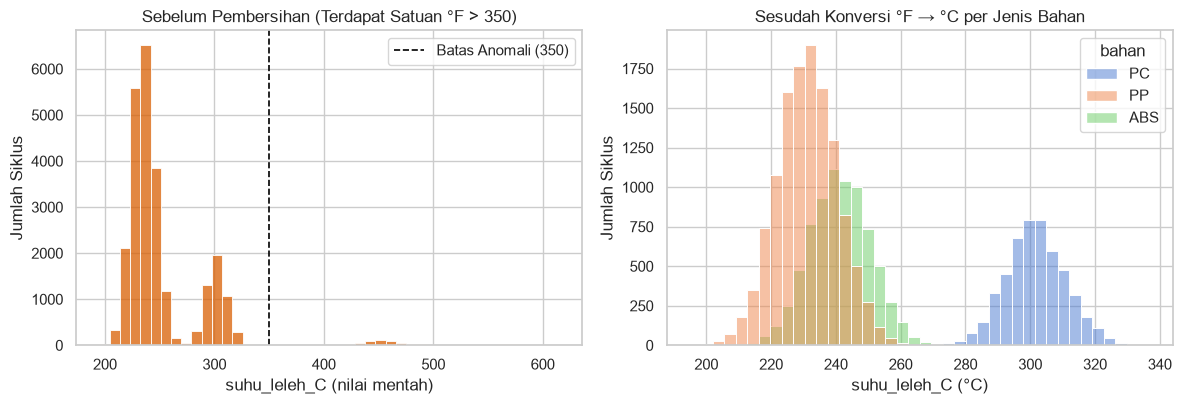

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

sns.histplot(raw["suhu_leleh_C"].dropna(), bins=45, ax=axes[0], color="#d95f02")
axes[0].axvline(350, color="black", linestyle="--", linewidth=1.2, label="Batas Anomali (350)")
axes[0].set_title("Sebelum Pembersihan (Terdapat Satuan °F > 350)")
axes[0].set_xlabel("suhu_leleh_C (nilai mentah)")
axes[0].set_ylabel("Jumlah Siklus")
axes[0].legend()

sns.histplot(data=clean, x="suhu_leleh_C", hue="bahan", bins=40, ax=axes[1])
axes[1].set_title("Sesudah Konversi °F → °C per Jenis Bahan")
axes[1].set_xlabel("suhu_leleh_C (°C)")
axes[1].set_ylabel("Jumlah Siklus")

plt.tight_layout()
fig.savefig("reports/figures/eda_suhu_leleh.png", dpi=200, bbox_inches="tight")
plt.show()

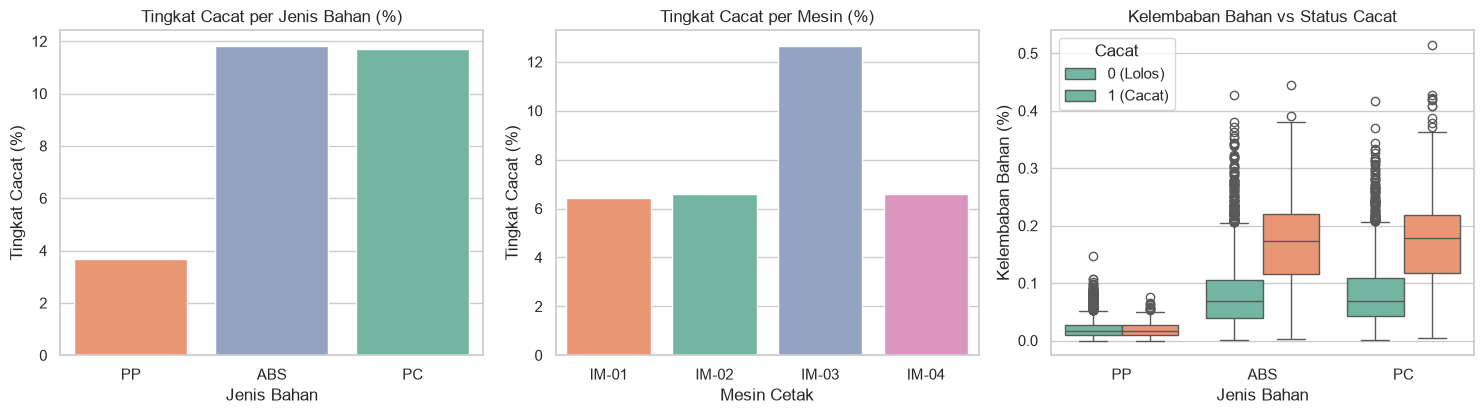

Rata-rata kelembaban ABS & PC berdasarkan status cacat:
cacat
0    0.0784
1    0.1703
Name: kelembaban_bahan_pct, dtype: float64


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))

sns.barplot(
    data=clean, x="bahan", y="cacat", hue="bahan", order=["PP", "ABS", "PC"],
    estimator=lambda x: np.mean(x) * 100, errorbar=None, legend=False, ax=axes[0], palette="Set2"
)
axes[0].set_title("Tingkat Cacat per Jenis Bahan (%)")
axes[0].set_xlabel("Jenis Bahan")
axes[0].set_ylabel("Tingkat Cacat (%)")

sns.barplot(
    data=clean, x="mesin", y="cacat", hue="mesin", order=["IM-01", "IM-02", "IM-03", "IM-04"],
    estimator=lambda x: np.mean(x) * 100, errorbar=None, legend=False, ax=axes[1], palette="Set2"
)
axes[1].set_title("Tingkat Cacat per Mesin (%)")
axes[1].set_xlabel("Mesin Cetak")
axes[1].set_ylabel("Tingkat Cacat (%)")

sns.boxplot(
    data=clean, x="bahan", y="kelembaban_bahan_pct", hue="cacat",
    order=["PP", "ABS", "PC"], ax=axes[2], palette={0: "#66c2a5", 1: "#fc8d62"}
)
axes[2].set_title("Kelembaban Bahan vs Status Cacat")
axes[2].set_xlabel("Jenis Bahan")
axes[2].set_ylabel("Kelembaban Bahan (%)")
axes[2].legend(title="Cacat", labels=["0 (Lolos)", "1 (Cacat)"])

plt.tight_layout()
fig.savefig("reports/figures/eda_faktor_cacat.png", dpi=200, bbox_inches="tight")
plt.show()

higro = clean[clean["bahan"].isin(["ABS", "PC"])]
print("Rata-rata kelembaban ABS & PC berdasarkan status cacat:")
print(higro.groupby("cacat")["kelembaban_bahan_pct"].mean().round(4))